# Linear and Quadratic Discriminant Analysis with covariance ellipsoid: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/classification/plot_lda_qda.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/classification/plot_lda_qda.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** three two-class Gaussian datasets (isotropic shared covariance, shared anisotropic
covariance, different covariances; `RandomState(0)`), each fitted with
`LinearDiscriminantAnalysis(solver="svd", store_covariance=True)` and
`QuadraticDiscriminantAnalysis(solver="svd", store_covariance=True)`. The gallery draws
`predict_proba` over a 100x100 grid (`DecisionBoundaryDisplay`), the 0.5 contour, the
misclassified training points from `predict`, `means_` and 2-sigma ellipses of `covariance_`.

**Beyond the gallery:** every learned attribute (`coef_`, `intercept_`, `xbar_`, `scalings_`,
`explained_variance_ratio_`, `priors_`, QDA `rotations_`/`scalings_`), `decision_function`,
`predict_log_proba`, `score`, and the same models in Float32.

**Adaptations:**
- Data are generated by the official `make_data` in Python and shared. sklearn's float targets
  `0.0`/`1.0` become typed `Int` labels `0`/`1` in Moxie (typed label domain, docs/interfaces.md).
- `DecisionBoundaryDisplay` is a Python plotting helper; its exact grid (`eps=1.0`,
  `grid_resolution=100`, `np.meshgrid` of `np.linspace`) is rebuilt in Python and shared, and the
  Moxie probabilities on it are drawn with the same `pcolormesh`/`contour` calls.
- QDA `covariance_` is `Optional[List[NDArray]]` and LDA's optional attributes are `Optional`
  (docs/discriminant_analysis/api.md).

**Determinism:** deterministic (fixed `RandomState(0)`, closed-form SVD solvers). All learned
attributes, decisions and probabilities are compared numerically; singular-vector signs are
aligned first because LAPACK and the native SVD may choose opposite signs.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("discriminant_analysis/plot_lda_qda")

## 1. scikit-learn (Python reference)

The official example code, unchanged except for figure size and capturing each fit's learned state.

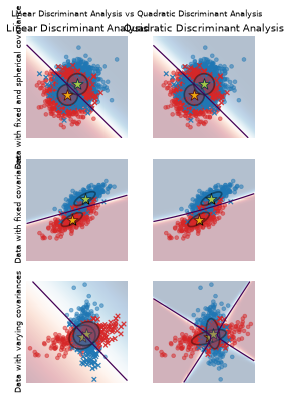

In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import colors
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis


def make_data(n_samples, n_features, cov_class_1, cov_class_2, seed=0):
    rng = np.random.RandomState(seed)
    X = np.concatenate(
        [
            rng.randn(n_samples, n_features) @ cov_class_1,
            rng.randn(n_samples, n_features) @ cov_class_2 + np.array([1, 1]),
        ]
    )
    y = np.concatenate([np.zeros(n_samples), np.ones(n_samples)])
    return X, y


covariance = np.array([[1, 0], [0, 1]])
X_isotropic_covariance, y_isotropic_covariance = make_data(
    n_samples=1_000, n_features=2, cov_class_1=covariance, cov_class_2=covariance, seed=0)
covariance = np.array([[0.0, -0.23], [0.83, 0.23]])
X_shared_covariance, y_shared_covariance = make_data(
    n_samples=300, n_features=2, cov_class_1=covariance, cov_class_2=covariance, seed=0)
cov_class_1 = np.array([[0.0, -1.0], [2.5, 0.7]]) * 2.0
cov_class_2 = cov_class_1.T
X_different_covariance, y_different_covariance = make_data(
    n_samples=300, n_features=2, cov_class_1=cov_class_1, cov_class_2=cov_class_2, seed=0)


def plot_ellipse(mean, cov, color, ax):
    v, w = np.linalg.eigh(cov)
    u = w[0] / np.linalg.norm(w[0])
    angle = np.arctan(u[1] / u[0])
    angle = 180 * angle / np.pi  # convert to degrees
    # filled Gaussian at 2 standard deviation
    ell = mpl.patches.Ellipse(mean, 2 * v[0] ** 0.5, 2 * v[1] ** 0.5, angle=180 + angle,
                              facecolor=color, edgecolor="black", linewidth=2)
    ell.set_clip_box(ax.bbox)
    ell.set_alpha(0.4)
    ax.add_artist(ell)


def plot_result(estimator, X, y, ax):
    cmap = colors.ListedColormap(["tab:red", "tab:blue"])
    DecisionBoundaryDisplay.from_estimator(estimator, X, response_method="predict_proba",
                                           plot_method="pcolormesh", ax=ax, cmap="RdBu", alpha=0.3)
    DecisionBoundaryDisplay.from_estimator(estimator, X, response_method="predict_proba",
                                           plot_method="contour", ax=ax, alpha=1.0, levels=[0.5])
    y_pred = estimator.predict(X)
    X_right, y_right = X[y == y_pred], y[y == y_pred]
    X_wrong, y_wrong = X[y != y_pred], y[y != y_pred]
    ax.scatter(X_right[:, 0], X_right[:, 1], c=y_right, s=20, cmap=cmap, alpha=0.5)
    ax.scatter(X_wrong[:, 0], X_wrong[:, 1], c=y_wrong, s=30, cmap=cmap, alpha=0.9, marker="x")
    ax.scatter(estimator.means_[:, 0], estimator.means_[:, 1], c="yellow", s=200, marker="*", edgecolor="black")
    if isinstance(estimator, LinearDiscriminantAnalysis):
        covariance = [estimator.covariance_] * 2
    else:
        covariance = estimator.covariance_
    plot_ellipse(estimator.means_[0], covariance[0], "tab:red", ax)
    plot_ellipse(estimator.means_[1], covariance[1], "tab:blue", ax)
    ax.set_box_aspect(1)
    for side in ("top", "bottom", "left", "right"):
        ax.spines[side].set_visible(False)
    ax.set(xticks=[], yticks=[])


fig, axs = plt.subplots(nrows=3, ncols=2, sharex="row", sharey="row", figsize=(5, 7.5), dpi=60)
lda = LinearDiscriminantAnalysis(solver="svd", store_covariance=True)
qda = QuadraticDiscriminantAnalysis(solver="svd", store_covariance=True)
DATA = list(zip((X_isotropic_covariance, X_shared_covariance, X_different_covariance),
                (y_isotropic_covariance, y_shared_covariance, y_different_covariance)))
sk = []  # learned state per dataset, captured right after each fit as in the gallery loop
for ax_row, (X, y) in zip(axs, DATA):
    lda.fit(X, y)
    plot_result(lda, X, y, ax_row[0])
    qda.fit(X, y)
    plot_result(qda, X, y, ax_row[1])
    sk.append(dict(
        lda={k: np.copy(getattr(lda, k)) for k in ("coef_", "intercept_", "means_", "priors_", "covariance_",
                                                     "xbar_", "scalings_", "explained_variance_ratio_")},
        qda=dict(means_=qda.means_.copy(), priors_=qda.priors_.copy(), covariance_=[c.copy() for c in qda.covariance_],
                 scalings_=[s.copy() for s in qda.scalings_], rotations_=[r.copy() for r in qda.rotations_])))
axs[0, 0].set_title("Linear Discriminant Analysis")
axs[0, 0].set_ylabel("Data with fixed and spherical covariance")
axs[1, 0].set_ylabel("Data with fixed covariance")
axs[0, 1].set_title("Quadratic Discriminant Analysis")
axs[2, 0].set_ylabel("Data with varying covariances")
fig.suptitle("Linear Discriminant Analysis vs Quadratic Discriminant Analysis", y=0.94, fontsize=10)
plt.show()

Prediction surfaces, decisions and Float32 fits beyond the gallery, plus the data shared with Moxie.

In [3]:
# The DecisionBoundaryDisplay grid (eps=1.0, grid_resolution=100), predictions and Float32 fits,
# recomputed per dataset; then the data are shared with Moxie (labels as Int).
def grid(X, eps=1.0, n=100):
    x0 = np.linspace(X[:, 0].min() - eps, X[:, 0].max() + eps, n)
    x1 = np.linspace(X[:, 1].min() - eps, X[:, 1].max() + eps, n)
    xx0, xx1 = np.meshgrid(x0, x1)
    return xx0, xx1, np.c_[xx0.ravel(), xx1.ravel()]

shared = {}
for d, (X, y) in enumerate(DATA):
    xx0, xx1, G = grid(X)
    lda_d = LinearDiscriminantAnalysis(solver="svd", store_covariance=True).fit(X, y)
    qda_d = QuadraticDiscriminantAnalysis(solver="svd", store_covariance=True).fit(X, y)
    sk[d].update(grid=(xx0, xx1),
                 lda_pred=lda_d.predict(X).astype(int), qda_pred=qda_d.predict(X).astype(int),
                 lda_grid=lda_d.predict_proba(G), qda_grid=qda_d.predict_proba(G),
                 lda_dec=lda_d.decision_function(X), qda_dec=qda_d.decision_function(X),
                 lda_logp=lda_d.predict_log_proba(X), qda_logp=qda_d.predict_log_proba(X),
                 scores=np.array([lda_d.score(X, y), qda_d.score(X, y)]))
    X32 = X.astype(np.float32)
    lda32 = LinearDiscriminantAnalysis(solver="svd", store_covariance=True).fit(X32, y)
    qda32 = QuadraticDiscriminantAnalysis(solver="svd", store_covariance=True).fit(X32, y)
    sk[d].update(lda32_coef=lda32.coef_, lda32_proba=lda32.predict_proba(X32),
                 qda32_proba=qda32.predict_proba(X32), dtypes=(lda32.coef_.dtype, qda32.means_.dtype))
    shared[f"X{d}"], shared[f"y{d}"], shared[f"G{d}"], shared[f"X32_{d}"] = X, y.astype(np.int64), G, X32
    print(f"dataset {d}: n={len(X)}  LDA acc={sk[d]['scores'][0]:.4f}  QDA acc={sk[d]['scores'][1]:.4f}"
          f"  float32 dtypes={sk[d]['dtypes']}")
nb.share(**shared)

dataset 0: n=2000  LDA acc=0.7605  QDA acc=0.7600  float32 dtypes=(dtype('float32'), dtype('float32'))
dataset 1: n=600  LDA acc=0.9417  QDA acc=0.9450  float32 dtypes=(dtype('float32'), dtype('float32'))
dataset 2: n=600  LDA acc=0.5950  QDA acc=0.7767  float32 dtypes=(dtype('float32'), dtype('float32'))


## 2. Moxie (native Mojo)

The same fits through `moxie.discriminant_analysis`; learning and prediction happen in Mojo.

In [4]:
%%mojo lda_qda
from numojo import NDArray
from moxie.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from moxie_nb_io import load, load_ints, save, save_ints, save_floats


def main() raises:
    for d in range(3):
        var tag = String(d)
        var X = load("X" + tag)
        var y = load_ints("y" + tag)
        var G = load("G" + tag)
        var lda = LinearDiscriminantAnalysis(solver="svd", store_covariance=True)
        var qda = QuadraticDiscriminantAnalysis(solver="svd", store_covariance=True)
        _ = lda.fit(X, y)
        _ = qda.fit(X, y)
        save("lda_coef_" + tag, lda.coef_)
        save("lda_intercept_" + tag, lda.intercept_)
        save("lda_means_" + tag, lda.means_)
        save("lda_priors_" + tag, lda.priors_)
        save("lda_covariance_" + tag, lda.covariance_.value())
        save("lda_xbar_" + tag, lda.xbar_.value())
        save("lda_scalings_" + tag, lda.scalings_.value())
        save("lda_evr_" + tag, lda.explained_variance_ratio_.value())
        save("qda_means_" + tag, qda.means_)
        save("qda_priors_" + tag, qda.priors_)
        for c in range(2):
            var ct = tag + "_" + String(c)
            save("qda_covariance_" + ct, qda.covariance_.value()[c])
            save("qda_scalings_" + ct, qda.scalings_[c])
            save("qda_rotations_" + ct, qda.rotations_[c])
        save_ints("lda_pred_" + tag, lda.predict(X))
        save_ints("qda_pred_" + tag, qda.predict(X))
        save("lda_grid_" + tag, lda.predict_proba(G))
        save("qda_grid_" + tag, qda.predict_proba(G))
        save("lda_dec_" + tag, lda.decision_function(X))
        save("qda_dec_" + tag, qda.decision_function(X))
        save("lda_logp_" + tag, lda.predict_log_proba(X))
        save("qda_logp_" + tag, qda.predict_log_proba(X))
        save_floats("scores_" + tag, [lda.score(X, y), qda.score(X, y)])
        # Float32: same estimators instantiated for DType.float32 (dtype is a type parameter).
        var X32 = load[DType.float32]("X32_" + tag)
        var lda32 = LinearDiscriminantAnalysis[DType.float32](solver="svd", store_covariance=True)
        var qda32 = QuadraticDiscriminantAnalysis[DType.float32](solver="svd", store_covariance=True)
        _ = lda32.fit(X32, y)
        _ = qda32.fit(X32, y)
        save("lda32_coef_" + tag, lda32.coef_)
        save("lda32_proba_" + tag, lda32.predict_proba(X32))
        save("qda32_proba_" + tag, qda32.predict_proba(X32))
        print("dataset", d, "classes_", lda.classes_, "LDA acc", lda.score(X, y), "QDA acc", qda.score(X, y))

dataset 0 classes_ [0, 1] LDA acc 0.7605 QDA acc 0.76
dataset 1 classes_ [0, 1] LDA acc 0.9416666666666667 QDA acc 0.945
dataset 2 classes_ [0, 1] LDA acc 0.595 QDA acc 0.7766666666666666


## 3. Side by side and parity

The gallery figure redrawn from both libraries' outputs (sklearn | Moxie per estimator), then numerical parity with justified tolerances.

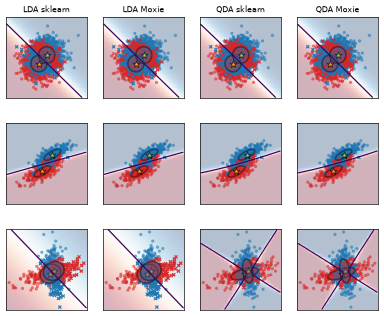

In [5]:
mx = nb.results["lda_qda"]
cmap = colors.ListedColormap(["tab:red", "tab:blue"])

def draw(ax, X, y, pred, proba, means, covs, grid_xy):
    xx0, xx1 = grid_xy
    ax.pcolormesh(xx0, xx1, proba[:, 1].reshape(xx0.shape), cmap="RdBu", alpha=0.3)
    ax.contour(xx0, xx1, proba[:, 1].reshape(xx0.shape), levels=[0.5])
    ok = y == pred
    ax.scatter(X[ok, 0], X[ok, 1], c=y[ok], s=8, cmap=cmap, alpha=0.5)
    ax.scatter(X[~ok, 0], X[~ok, 1], c=y[~ok], s=14, cmap=cmap, alpha=0.9, marker="x")
    ax.scatter(means[:, 0], means[:, 1], c="yellow", s=80, marker="*", edgecolor="black")
    plot_ellipse(means[0], covs[0], "tab:red", ax)
    plot_ellipse(means[1], covs[1], "tab:blue", ax)
    ax.set_box_aspect(1); ax.set(xticks=[], yticks=[])

fig, axs = plt.subplots(3, 4, figsize=(8, 6.5), dpi=60)
for d, (X, y) in enumerate(DATA):
    t = str(d); yi = y.astype(int)
    draw(axs[d, 0], X, yi, sk[d]["lda_pred"], sk[d]["lda_grid"], sk[d]["lda"]["means_"], [sk[d]["lda"]["covariance_"]] * 2, sk[d]["grid"])
    draw(axs[d, 1], X, yi, mx[f"lda_pred_{t}"], mx[f"lda_grid_{t}"], mx[f"lda_means_{t}"], [mx[f"lda_covariance_{t}"]] * 2, sk[d]["grid"])
    draw(axs[d, 2], X, yi, sk[d]["qda_pred"], sk[d]["qda_grid"], sk[d]["qda"]["means_"], sk[d]["qda"]["covariance_"], sk[d]["grid"])
    draw(axs[d, 3], X, yi, mx[f"qda_pred_{t}"], mx[f"qda_grid_{t}"], mx[f"qda_means_{t}"],
         [mx[f"qda_covariance_{t}_0"], mx[f"qda_covariance_{t}_1"]], sk[d]["grid"])
for ax, title in zip(axs[0], ["LDA sklearn", "LDA Moxie", "QDA sklearn", "QDA Moxie"]):
    ax.set_title(title, fontsize=9)
plt.show()
moxie_nb.side_by_side(
    sklearn={f"d{d} LDA/QDA acc": f"{sk[d]['scores'][0]:.4f} / {sk[d]['scores'][1]:.4f}" for d in range(3)},
    moxie={f"d{d} LDA/QDA acc": f"{mx[f'scores_{d}'][0]:.4f} / {mx[f'scores_{d}'][1]:.4f}" for d in range(3)})

In [6]:
def align(ref, got):
    """Flip each column of `got` to the sign of `ref` (singular/eigenvector signs are unspecified)."""
    got = np.array(got, dtype=np.float64)
    for j in range(got.shape[1]):
        if np.dot(ref[:, j], got[:, j]) < 0:
            got[:, j] = -got[:, j]
    return got

F64 = ("Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and "
       "different summation order give differences of a few ulps times the conditioning of these "
       "well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom")
for d in range(3):
    t = str(d); L, Q = sk[d]["lda"], sk[d]["qda"]
    for key, mkey in [("coef_", "coef"), ("intercept_", "intercept"), ("means_", "means"), ("priors_", "priors"),
                      ("covariance_", "covariance"), ("xbar_", "xbar"), ("explained_variance_ratio_", "evr")]:
        nb.compare(f"d{d} LDA {key}", L[key], mx[f"lda_{mkey}_{t}"], rtol=1e-9, atol=1e-12, reason=F64)
    nb.compare(f"d{d} LDA scalings_ (sign-aligned)", L["scalings_"], align(L["scalings_"], mx[f"lda_scalings_{t}"]),
               rtol=1e-9, atol=1e-12, reason=F64 + "; column signs aligned")
    nb.compare(f"d{d} LDA predict", sk[d]["lda_pred"], mx[f"lda_pred_{t}"], exact=True)
    nb.compare(f"d{d} LDA decision_function", sk[d]["lda_dec"], mx[f"lda_dec_{t}"], rtol=1e-9, atol=1e-10, reason=F64)
    nb.compare(f"d{d} LDA predict_proba (100x100 grid)", sk[d]["lda_grid"], mx[f"lda_grid_{t}"], rtol=0, atol=1e-10,
               reason="expit of decisions agreeing to ~1e-12; probabilities are bounded by 1")
    nb.compare(f"d{d} LDA predict_log_proba", sk[d]["lda_logp"], mx[f"lda_logp_{t}"], rtol=1e-8, atol=1e-10, reason=F64)
    nb.compare(f"d{d} QDA means_", Q["means_"], mx[f"qda_means_{t}"], rtol=1e-12, atol=1e-14, reason="class means; summation order")
    nb.compare(f"d{d} QDA priors_", Q["priors_"], mx[f"qda_priors_{t}"], exact=True)
    for c in range(2):
        ct = f"{t}_{c}"
        nb.compare(f"d{d} QDA covariance_[{c}]", Q["covariance_"][c], mx[f"qda_covariance_{ct}"], rtol=1e-9, atol=1e-12, reason=F64)
        nb.compare(f"d{d} QDA scalings_[{c}]", Q["scalings_"][c], mx[f"qda_scalings_{ct}"], rtol=1e-9, atol=1e-12, reason=F64)
        nb.compare(f"d{d} QDA rotations_[{c}] (sign-aligned)", Q["rotations_"][c],
                   align(Q["rotations_"][c], mx[f"qda_rotations_{ct}"]), rtol=1e-9, atol=1e-11,
                   reason=F64 + "; column signs aligned (eigenvalues are well separated here)")
    nb.compare(f"d{d} QDA predict", sk[d]["qda_pred"], mx[f"qda_pred_{t}"], exact=True)
    nb.compare(f"d{d} QDA decision_function", sk[d]["qda_dec"], mx[f"qda_dec_{t}"], rtol=1e-9, atol=1e-10, reason=F64)
    nb.compare(f"d{d} QDA predict_proba (100x100 grid)", sk[d]["qda_grid"], mx[f"qda_grid_{t}"], rtol=0, atol=1e-10,
               reason="softmax of log-posteriors agreeing to ~1e-12")
    nb.compare(f"d{d} QDA predict_log_proba", sk[d]["qda_logp"], mx[f"qda_logp_{t}"], rtol=1e-8, atol=1e-10, reason=F64)
    nb.compare(f"d{d} score (LDA, QDA)", sk[d]["scores"], mx[f"scores_{t}"], exact=True)
    F32 = ("sklearn evaluates parts of the Float32 path in single precision while Moxie accumulates in Float64 and "
           "rounds once (docs/discriminant_analysis/api.md); single-precision eps 1.2e-7 times conditioning")
    nb.compare(f"d{d} Float32 LDA coef_", sk[d]["lda32_coef"], mx[f"lda32_coef_{t}"], rtol=1e-4, atol=1e-5, reason=F32)
    nb.compare(f"d{d} Float32 LDA predict_proba", sk[d]["lda32_proba"], mx[f"lda32_proba_{t}"], rtol=0, atol=1e-4, reason=F32)
    nb.compare(f"d{d} Float32 QDA predict_proba", sk[d]["qda32_proba"], mx[f"qda32_proba_{t}"], rtol=0, atol=1e-4, reason=F32)
    assert mx[f"lda32_coef_{t}"].dtype == np.float32 and mx[f"qda32_proba_{t}"].dtype == np.float32
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
d0 LDA coef_,PASS,"(1, 2)","(1, 2)",8.22e-15,8.25e-15,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
d0 LDA intercept_,PASS,"(1,)","(1,)",5.55e-15,5.7e-15,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
d0 LDA means_,PASS,"(2, 2)","(2, 2)",0,0,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
d0 LDA priors_,PASS,"(2,)","(2,)",0,0,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
d0 LDA covariance_,PASS,"(2, 2)","(2, 2)",2.22e-16,2.31e-16,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
d0 LDA xbar_,PASS,"(2,)","(2,)",0,0,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
d0 LDA explained_variance_ratio_,PASS,"(1,)","(1,)",0,0,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
d0 LDA scalings_ (sign-aligned),PASS,"(2, 1)","(2, 1)",3.77e-15,5.38e-15,"rtol=1e-09, atol=1e-12",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom; column signs aligned
d0 LDA predict,PASS,"(2000,)","(2000,)",,,exact,0 mismatches,
d0 LDA decision_function,PASS,"(2000,)","(2000,)",4.44e-14,2.92e-12,"rtol=1e-09, atol=1e-10",,Float64 on both sides; two economy SVDs (native one-sided Jacobi vs LAPACK gesdd) and different summation order give differences of a few ulps times the conditioning of these well-conditioned 2-feature problems (<1e-12 relative); 1e-9 leaves headroom
